# Tendencia de clustering en los 164 segmentos sexo × edad (Hopkins y VAT) · Perfiles de votantes

**Proyecto:** Hackathon INE 2026 · Reto 1 · Perfiles ciudadanos de participación.
Complementa `tendencia_clustering.ipynb` y `tendencia_clustering_forma.ipynb`, y se relaciona con [`reports/perfiles_sexo_edad/`](../reports/perfiles_sexo_edad/README.md).

## Pregunta que responde
Los cuatro perfiles de `perfiles_sexo_edad` se obtuvieron agrupando **164 segmentos** (sexo × edad simple de 18 a 99 años), cada uno descrito por su participación nacional en las 6 elecciones. Los notebooks anteriores probaron otra tabla (1,458 unidades por entidad × sexo × grupo de edad × sección). Aquí se aplica Hopkins y VAT **a la misma tabla de 164 segmentos que se agrupó**: ¿forman grupos naturales o son una curva continua cortada en cuatro?

## Cómo se prueba (y por qué hay un nulo de curva)
Con 164 puntos que son **dos curvas finas** (una por sexo, la participación cambia con la edad), Hopkins sube con cualquier estructura delgada, no solo con grupos. La nube gaussiana con la misma covarianza que usan los otros notebooks no tiene esa forma, así que **no es una comparación justa aquí**. Por eso se agrega un tercer nulo, el **nulo de curva continua**:
1. Para cada sexo y cada elección se ajusta una curva suave (polinomio) de la participación estandarizada contra la edad.
2. Se generan 164 puntos nuevos en las mismas edades y sexos, sobre esa curva suave, con ruido igual al residuo del ajuste.
Es una población que **por construcción es continua** (sin saltos ni cortes) y tiene la misma forma, el mismo ruido y el mismo muestreo por edad. Lo que cuenta es `delta_curva = H_real − H_curva`: cuánta tendencia hay **más allá de una curva continua**. Los nulos gaussiano y de columnas permutadas se reportan por comparabilidad con los otros notebooks.

Además de Hopkins, se mide si hay **saltos** entre edades vecinas en las fronteras de los perfiles, contra lo que se esperaría de la curva continua.

## Reglas de decisión (fijadas antes de ejecutar)
- **Continuo:** `delta_curva` < 0.05 **y** el contraste de saltos en las fronteras (sección 6) no supera el percentil 90 del nulo de curva.
- **Grupos naturales:** `delta_curva` > 0.10 **y** el contraste de saltos supera el percentil 90 del nulo de curva.
- **Ambiguo:** cualquier otro caso; se reporta tal cual.

## Alcance
Entra: Hopkins, saltos y VAT sobre la tabla de 164 segmentos. **No entra**: el clustering en sí, el efecto entidad ni la sección (la tabla es nacional) ni causas.

## Índice
1. Entorno · 2. Carga y validación · 3. Funciones · 4. Hopkins (con el nulo de curva) · 5. Saltos entre edades vecinas · 6. Imágenes VAT · 7. Autopruebas · 8. Conclusiones

## 1. Entorno

In [1]:
import platform
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score as ari

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'reports/perfiles_sexo_edad').exists())
ASIG = ROOT / 'reports/perfiles_sexo_edad/asignacion_segmentos_sexo_edad.csv'
COMP = ROOT / 'reports/perfiles_sexo_edad/perfiles_edad_sexo_comparacion.csv'
OUT = ROOT / 'reports/local/tendencia_segmentos'
OUT.mkdir(parents=True, exist_ok=True)

YEARS = [2009, 2012, 2015, 2018, 2021, 2024]
REPS = 200          # repeticiones de Hopkins
GRADOS = (6, 10)    # grados del polinomio del nulo de curva
NDRAW = 50          # realizaciones del nulo de curva en Hopkins
NDRAW_SALTOS = 200  # realizaciones del nulo de curva en el contraste de saltos

print(f'Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · '
      f'scipy {scipy.__version__} · scikit-learn {sklearn.__version__} · matplotlib {matplotlib.__version__}')

Python 3.14.8 · numpy 2.5.4 · pandas 3.1.0 · scipy 1.18.1 · scikit-learn 1.9.1 · matplotlib 3.11.2


## 2. Carga y validación
Se lee `asignacion_segmentos_sexo_edad.csv`, que contiene la tabla exacta que se agrupó (participación en % por sexo × edad × elección y el perfil asignado). Antes de analizar se comprueba que es la misma matriz y el mismo agrupamiento de `scripts/17_perfiles_edad_sexo.py`:
1. 164 filas (2 sexos × edades 18 a 99), sin vacíos.
2. La silhouette de k-means con k = 2 a 6 coincide con `perfiles_edad_sexo_comparacion.csv`.
3. El agrupamiento con k = 4 coincide con `perfil_numero` (ARI = 1).
4. Una celda coincide con los datos originales (si la carpeta de crudos de 2024 está disponible).

In [2]:
seg = pd.read_csv(ASIG).set_index(['SEXO', 'EDAD'])
P = seg[[str(y) for y in YEARS]]
sexos = P.index.get_level_values('SEXO').to_numpy()
edades = P.index.get_level_values('EDAD').to_numpy()
perfil = seg.perfil_numero.to_numpy()

assert len(P) == 164 and P.notna().all().all()
assert set(sexos) == {0, 1} and sorted(set(edades)) == list(range(18, 100))
Z = StandardScaler().fit_transform(P.values)   # igual que scripts/17

comp = pd.read_csv(COMP)
for k in range(2, 7):
    sil = silhouette_score(Z, KMeans(k, n_init=30, random_state=SEED).fit_predict(Z))
    ref = comp.query('k == @k and algoritmo == "kmeans"').silhouette.iloc[0]
    assert abs(sil - ref) < 0.0015, (k, sil, ref)
lab4 = KMeans(4, n_init=50, random_state=SEED).fit_predict(Z)
assert ari(lab4, perfil) == 1.0, ari(lab4, perfil)
print('Silhouette k=2..6 y agrupamiento con k=4 coinciden con perfiles_sexo_edad.')

crudos = ROOT / 'data/raw/DatosAbiertos_DECEyEC_ConteosCensales2024'
if crudos.exists():
    r = pd.concat(pd.read_csv(f, encoding='utf-8-sig', usecols=['SEXO', 'EDAD', 'SV', 'NV']) for f in sorted(crudos.glob('*.csv')))
    r = r[(r.SEXO == 0) & (r.EDAD == 18)]
    p = 100 * r.SV.sum() / (r.SV.sum() + r.NV.sum())
    assert abs(p - P.loc[(0, 18), '2024']) < 5e-4, (p, P.loc[(0, 18), '2024'])
    print(f'Celda hombres 18 años 2024 coincide con los crudos: {p:.3f} %')
else:
    print('Crudos de 2024 no encontrados; se omite la comparación con el CSV original.')
pd.DataFrame({'segmentos': len(P), 'hombres': (sexos == 0).sum(), 'mujeres': (sexos == 1).sum()}, index=['n']).T

Silhouette k=2..6 y agrupamiento con k=4 coinciden con perfiles_sexo_edad.


Celda hombres 18 años 2024 coincide con los crudos: 57.857 %


,n
segmentos,164
hombres,82
mujeres,82


## 3. Funciones
`hopkins` y `vat` son las mismas de los otros notebooks (se copian para que este corra solo). Los tres nulos:
- **`gauss`**: nube gaussiana con la misma media y covarianza (sin forma de curva).
- **`perm`**: columnas permutadas.
- **`curva`**: curva continua (sección "Cómo se prueba" arriba). `ajuste_curva` ajusta un polinomio de grado `grado` en la edad, por sexo y elección; `curva_nula` genera un conjunto nuevo sobre esa curva con el mismo ruido.

In [3]:
def hopkins(X, m=None, reps=REPS, seed=SEED):
    """Estadístico de Hopkins: devuelve (media, desviación estándar) en `reps` repeticiones.

    X: matriz (n, d). m: tamaño de muestra (por defecto 10 % de n, mínimo 10).
    """
    rng = np.random.default_rng(seed)
    n, dim = X.shape
    m = m or max(10, n // 10)
    tree = cKDTree(X)
    lo, hi = X.min(0), X.max(0)
    hs = []
    for _ in range(reps):
        w = tree.query(X[rng.choice(n, m, replace=False)], k=2)[0][:, 1]   # vecino más cercano distinto de sí mismo
        u = tree.query(rng.uniform(lo, hi, (m, dim)), k=1)[0]
        hs.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(hs)), float(np.std(hs))


def vat(X):
    """Matriz de distancias reordenada (VAT): devuelve (matriz n×n, orden de filas)."""
    D = squareform(pdist(X))
    n = len(D)
    first = int(np.unravel_index(D.argmax(), D.shape)[0])
    order, rest = [first], np.ones(n, bool)
    rest[first] = False
    near = D[first].copy()
    for _ in range(n - 1):
        j = int(np.argmin(np.where(rest, near, np.inf)))
        order.append(j)
        rest[j] = False
        near = np.minimum(near, D[j])
    return D[np.ix_(order, order)], np.array(order)


def veredicto(h, delta):
    """Misma regla heurística de los otros notebooks (umbrales exploratorios)."""
    if h > 0.75 and delta > 0.10: return 'clara'
    if h > 0.60 and delta > 0.05: return 'moderada'
    return 'sin evidencia'


def nulos(X, seed=SEED):
    """Referencias sin grupos: gaussiana con igual media/covarianza y columnas permutadas."""
    rng = np.random.default_rng(seed)
    return {'gauss': rng.multivariate_normal(X.mean(0), np.cov(X.T), len(X)),
            'perm': np.column_stack([rng.permutation(c) for c in X.T])}


def ajuste_curva(Z, grado):
    """Curva suave por sexo y elección (polinomio en la edad). Devuelve (valores ajustados, desviación del residuo por sexo y elección)."""
    mu, sd = np.empty_like(Z), np.empty((2, Z.shape[1]))
    for s in (0, 1):
        m = sexos == s
        for j in range(Z.shape[1]):
            f = Polynomial.fit(edades[m], Z[m, j], grado)
            mu[m, j] = f(edades[m])
            sd[s, j] = (Z[m, j] - mu[m, j]).std(ddof=grado + 1)
    return mu, sd


def curva_nula(mu, sd, rng):
    """Conjunto continuo por construcción: la curva ajustada más ruido igual al residuo."""
    return mu + rng.normal(size=mu.shape) * sd[sexos]


curvas = {g: ajuste_curva(Z, g) for g in GRADOS}
print('Desviación media del residuo (unidades estandarizadas; los datos tienen desviación 1):')
pd.DataFrame({f'grado {g}': curvas[g][1].mean(axis=1) for g in GRADOS}, index=['hombres', 'mujeres']).round(3)

Desviación media del residuo (unidades estandarizadas; los datos tienen desviación 1):


,grado 6,grado 10
hombres,0.046,0.036
mujeres,0.048,0.032


## 4. Hopkins (con el nulo de curva)
Se reporta con `m = 16` (10 % de n, como en los otros notebooks) y con `m = 32` como sensibilidad, porque con 164 puntos Hopkins es más ruidoso. Para el nulo de curva se promedian `NDRAW` realizaciones y se reporta la desviación **entre realizaciones**.

In [4]:
def h_curva(mu, sd, m, ndraw=NDRAW):
    """Hopkins medio sobre `ndraw` realizaciones del nulo de curva; devuelve (media, desviación entre realizaciones)."""
    rng = np.random.default_rng(SEED)
    hs = [hopkins(curva_nula(mu, sd, rng), m=m, reps=20, seed=i)[0] for i in range(ndraw)]
    return float(np.mean(hs)), float(np.std(hs))


rows = []
for m in (16, 32):
    h, sd_ = hopkins(Z, m=m)
    nul = nulos(Z)
    hg, hp = hopkins(nul['gauss'], m=m)[0], hopkins(nul['perm'], m=m)[0]
    for g in GRADOS:
        hc, sdc = h_curva(*curvas[g], m=m)
        rows.append({'m': m, 'grado_curva': g, 'n': len(Z), 'H_real': round(h, 3), 'sd': round(sd_, 3),
                     'H_gauss': round(hg, 3), 'H_perm': round(hp, 3), 'H_curva': round(hc, 3), 'sd_curva': round(sdc, 3),
                     'delta_gauss': round(h - hg, 3), 'delta_curva': round(h - hc, 3),
                     'veredicto_vs_curva': veredicto(h, h - hc)})
resumen = pd.DataFrame(rows)
resumen.to_csv(OUT / 'resumen_hopkins_segmentos.csv', index=False)
resumen

,m,grado_curva,n,H_real,sd,H_gauss,H_perm,H_curva,sd_curva,delta_gauss,delta_curva,veredicto_vs_curva
0,16,6,164,0.946,0.007,0.936,0.604,0.929,0.003,0.010,0.017,sin evidencia
1,16,10,164,0.946,0.007,0.936,0.604,0.937,0.002,0.010,0.009,sin evidencia
2,32,6,164,0.946,0.005,0.935,0.606,0.930,0.002,0.011,0.016,sin evidencia
3,32,10,164,0.946,0.005,0.935,0.606,0.937,0.002,0.011,0.009,sin evidencia


## 5. Saltos entre edades vecinas
Si hubiera cortes naturales, la distancia entre la edad *a* y la *a*+1 (mismo sexo) daría **saltos** en las fronteras de los perfiles. Pero un paso grande por sí solo no prueba un corte: la curva cambia más rápido en algunas edades (jóvenes y muy mayores), y k-means tiende a cortar justo ahí. Por eso se mide el **contraste local**: paso en la frontera ÷ promedio de los pasos vecinos (±3 edades). Un salto real daría un contraste mucho mayor que 1; una curva continua, cercano a 1.

Se compara contra el nulo de curva: `NDRAW_SALTOS` conjuntos continuos se agrupan con **el mismo procedimiento** (k-means, k = 4) y se calcula el mismo contraste. `p_empirico` es la fracción de nulos con contraste promedio igual o mayor que el real.

**Sensibilidad (se agregó después de ver el primer resultado y no cambia el veredicto formal):** una frontera cae en el borde del rango (edad 18-19), donde la curva cae abruptamente y el polinomio del nulo la suaviza. Se repite el contraste **sin** las fronteras con edad < 20, tanto en los datos reales como en el nulo (columnas `*_sin_borde`).

In [5]:
VENT = 3


def pasos(Z):
    """Distancia entre edades consecutivas, por sexo. Devuelve DataFrame (sexo, edad_a, paso)."""
    out = []
    for s in (0, 1):
        o = np.where(sexos == s)[0]
        o = o[np.argsort(edades[o])]
        out.append(pd.DataFrame({'sexo': s, 'edad_a': edades[o][:-1], 'paso': np.linalg.norm(np.diff(Z[o], axis=0), axis=1)}))
    return pd.concat(out, ignore_index=True)


def contraste_fronteras(Z, lab, vent=VENT):
    """Contraste local (paso en la frontera / promedio de pasos vecinos) en cada cambio de perfil. Devuelve DataFrame."""
    filas = []
    for s in (0, 1):
        o = np.where(sexos == s)[0]
        o = o[np.argsort(edades[o])]
        d = np.linalg.norm(np.diff(Z[o], axis=0), axis=1)
        l = lab[o]
        for i in np.where(l[:-1] != l[1:])[0]:
            vec = np.r_[d[max(0, i - vent):i], d[i + 1:i + 1 + vent]]
            filas.append({'sexo': s, 'edad_frontera': int(edades[o][i]), 'paso': d[i], 'contraste': d[i] / vec.mean()})
    return pd.DataFrame(filas)


paso = pasos(Z)
paso.to_csv(OUT / 'pasos_entre_edades.csv', index=False)
real = contraste_fronteras(Z, lab4)
real.to_csv(OUT / 'contraste_fronteras.csv', index=False)
print('Fronteras de los perfiles en los datos reales:')
display(real.round(2))

real_sin = real[real.edad_frontera >= 20]   # sensibilidad (posterior al resultado): sin las fronteras en el borde del rango (edad 18-19)
rng = np.random.default_rng(SEED)
salto_rows = []
for g in GRADOS:
    mu, sd = curvas[g]
    nulo, nulo_sin = [], []
    for _ in range(NDRAW_SALTOS):
        Zn = curva_nula(mu, sd, rng)
        c = contraste_fronteras(Zn, KMeans(4, n_init=10, random_state=SEED).fit_predict(Zn))
        if len(c): nulo.append(c.contraste.mean())
        if (c.edad_frontera >= 20).any(): nulo_sin.append(c[c.edad_frontera >= 20].contraste.mean())
    nulo, nulo_sin = np.array(nulo), np.array(nulo_sin)
    salto_rows.append({'grado_curva': g, 'fronteras_reales': len(real), 'contraste_real_prom': round(real.contraste.mean(), 2),
                       'nulo_p50': round(np.percentile(nulo, 50), 2), 'nulo_p90': round(np.percentile(nulo, 90), 2),
                       'nulo_p95': round(np.percentile(nulo, 95), 2), 'p_empirico': round(float((nulo >= real.contraste.mean()).mean()), 3),
                       'contraste_real_sin_borde': round(real_sin.contraste.mean(), 2), 'nulo_sin_borde_p90': round(np.percentile(nulo_sin, 90), 2),
                       'p_empirico_sin_borde': round(float((nulo_sin >= real_sin.contraste.mean()).mean()), 3)})
saltos = pd.DataFrame(salto_rows)
saltos.to_csv(OUT / 'resumen_saltos.csv', index=False)
saltos

Fronteras de los perfiles en los datos reales:


,sexo,edad_frontera,paso,contraste
0,0,19,0.61,1.20
1,0,36,0.18,1.08
2,0,51,0.12,1.00
3,0,81,0.31,1.02
4,0,87,0.51,1.14
5,0,92,0.51,1.17
6,1,18,1.16,4.25
7,1,38,0.12,0.94
8,1,77,0.38,1.36
9,1,83,0.41,0.98


,grado_curva,fronteras_reales,contraste_real_prom,nulo_p50,nulo_p90,nulo_p95,p_empirico,contraste_real_sin_borde,nulo_sin_borde_p90,p_empirico_sin_borde
0,6,11,1.37,1.10,1.21,1.23,0.0,1.07,1.20,0.570
1,10,11,1.37,1.19,1.27,1.29,0.0,1.07,1.15,0.445


## 6. Imágenes VAT
**Primera fila:** VAT de los datos reales, del nulo gaussiano y del nulo de curva (grado 10). Oscuro = cercano; los grupos serían cuadrados oscuros en la diagonal.
**Segunda fila:** (a) la matriz de distancias sin reordenar, con los segmentos ordenados por sexo y edad; (b) la posición de cada segmento en el orden del VAT frente a su edad, para ver si el VAT solo recupera el orden por edad; (c) los pasos entre edades vecinas por sexo, con las fronteras de los perfiles.

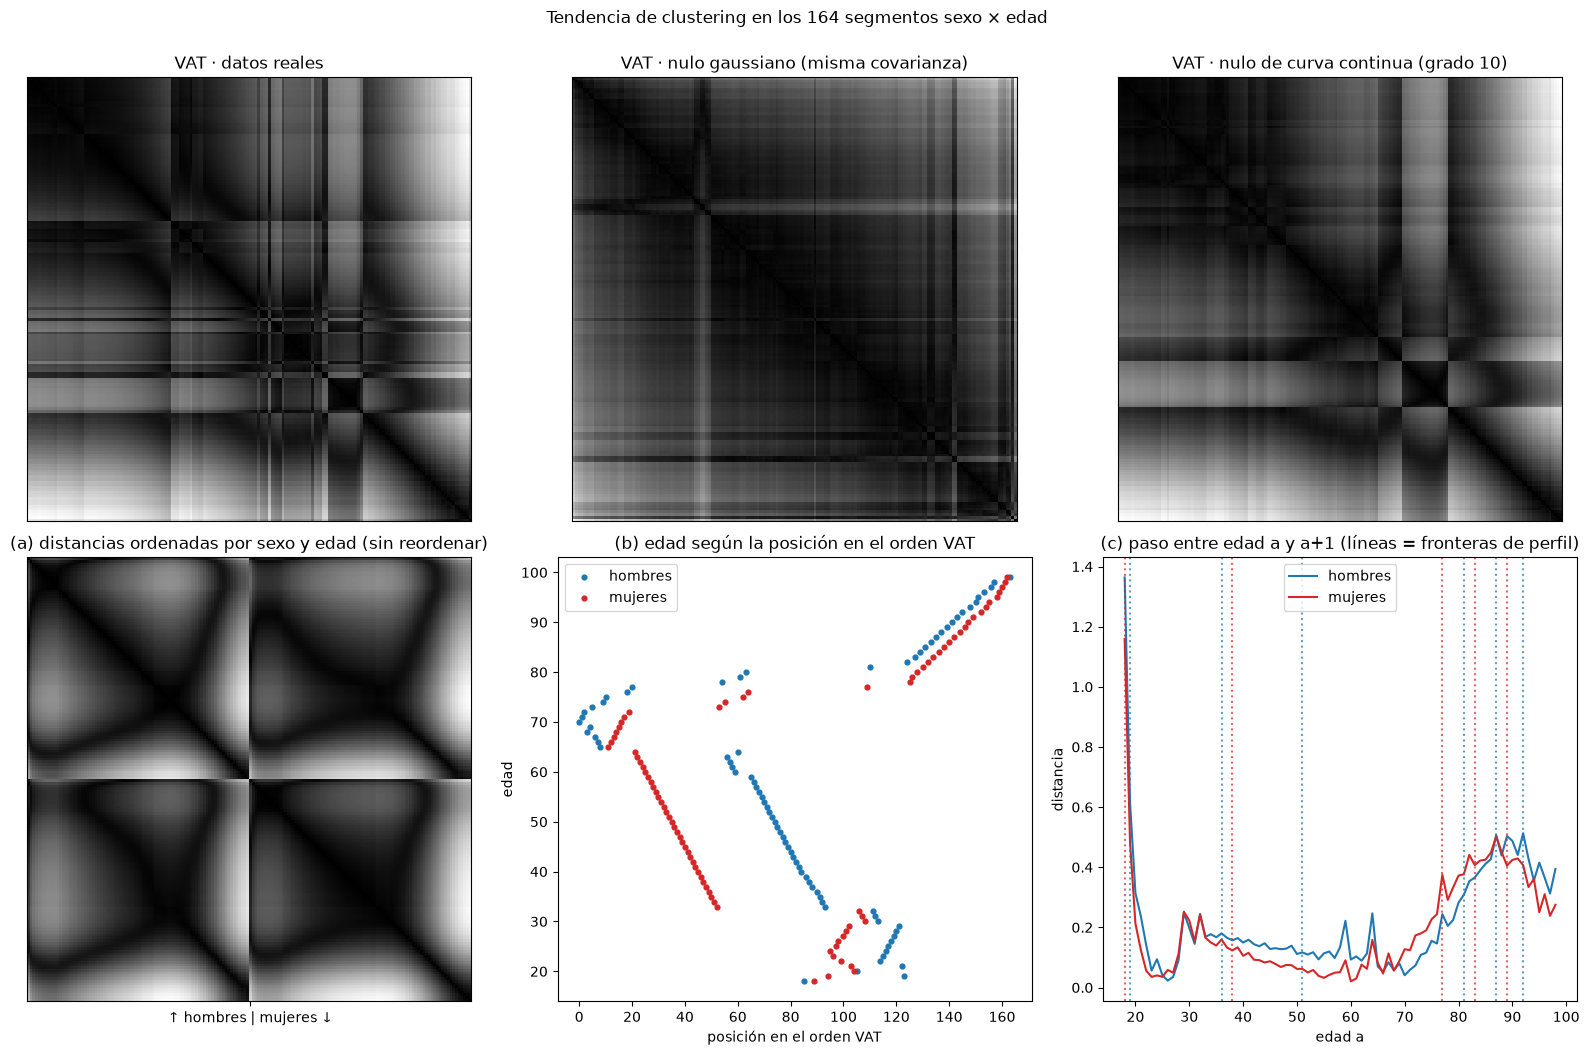

In [6]:
Zc = curva_nula(*curvas[10], np.random.default_rng(SEED))
paneles = [(Z, 'datos reales'), (nulos(Z)['gauss'], 'nulo gaussiano (misma covarianza)'), (Zc, 'nulo de curva continua (grado 10)')]
fig, axs = plt.subplots(2, 3, figsize=(16, 10.5))
for ax, (X, t) in zip(axs[0], paneles):
    ax.imshow(vat(X)[0], cmap='gray', interpolation='nearest')
    ax.set(title=f'VAT · {t}', xticks=[], yticks=[])

orden_se = np.lexsort((edades, sexos))                       # sexo y luego edad
axs[1, 0].imshow(squareform(pdist(Z))[np.ix_(orden_se, orden_se)], cmap='gray', interpolation='nearest')
axs[1, 0].set(title='(a) distancias ordenadas por sexo y edad (sin reordenar)', xticks=[82], xticklabels=['↑ hombres | mujeres ↓'], yticks=[])

orden_vat = vat(Z)[1]
for s, c, n in ((0, '#1f77b4', 'hombres'), (1, '#d62728', 'mujeres')):
    m = sexos[orden_vat] == s
    axs[1, 1].scatter(np.where(m)[0], edades[orden_vat][m], s=12, c=c, label=n)
axs[1, 1].set(title='(b) edad según la posición en el orden VAT', xlabel='posición en el orden VAT', ylabel='edad')
axs[1, 1].legend()

for s, c, n in ((0, '#1f77b4', 'hombres'), (1, '#d62728', 'mujeres')):
    q = paso[paso.sexo == s]
    axs[1, 2].plot(q.edad_a, q.paso, c=c, label=n)
for _, f in real.iterrows():
    axs[1, 2].axvline(f.edad_frontera, c='#1f77b4' if f.sexo == 0 else '#d62728', ls=':', alpha=.7)
axs[1, 2].set(title='(c) paso entre edad a y a+1 (líneas = fronteras de perfil)', xlabel='edad a', ylabel='distancia')
axs[1, 2].legend()
fig.suptitle(f'Tendencia de clustering en los {len(Z)} segmentos sexo × edad', y=1.0)
fig.tight_layout()
fig.savefig(OUT / 'vat_segmentos.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Autopruebas
1. Hopkins sobre datos uniformes ≈ 0.5.
2. Hopkins sobre dos nubes bien separadas > 0.85.
3. `vat` devuelve una permutación válida.
4. El nulo de curva con ruido 0 reproduce la curva ajustada; y un salto artificial sí sube el contraste de fronteras (la prueba detecta lo que debe detectar).

In [7]:
rng = np.random.default_rng(SEED)
h_unif = hopkins(rng.uniform(size=(600, 3)))[0]
h_blobs = hopkins(np.vstack([rng.normal(0, .3, (300, 3)), rng.normal(5, .3, (300, 3))]))[0]
assert 0.4 < h_unif < 0.6, h_unif
assert h_blobs > 0.85, h_blobs
assert sorted(vat(rng.normal(size=(50, 3)))[1]) == list(range(50))

mu0, _ = curvas[10]
assert np.allclose(curva_nula(mu0, np.zeros((2, 6)), rng), mu0)
Zs = mu0.copy()
Zs[(edades >= 50)] += 3          # salto artificial a los 50 años en ambos sexos
lab_s = (edades >= 50).astype(int) + 2 * sexos
assert contraste_fronteras(Zs, lab_s).contraste.mean() > 3, 'la prueba no detecta un salto artificial'
assert contraste_fronteras(mu0, lab_s).contraste.mean() < 2, 'una curva continua no debería dar contraste alto'
print(f'Hopkins uniforme={h_unif:.3f} (≈0.5) · dos nubes={h_blobs:.3f} (>0.85) · VAT ok · la prueba de saltos detecta saltos artificiales')

Hopkins uniforme=0.494 (≈0.5) · dos nubes=0.965 (>0.85) · VAT ok · la prueba de saltos detecta saltos artificiales


## 8. Conclusiones

_Resultados de la ejecución con `asignacion_segmentos_sexo_edad.csv` del 2026-10-29 (semilla 42; Hopkins con 200 repeticiones; nulo de curva con polinomios de grado 6 y 10). Si cambia el agrupamiento publicado, volver a ejecutar y revisar este texto._

**Veredicto formal (regla fijada antes de ejecutar): ambiguo.** Hopkins cumple la condición de "continuo", pero el contraste de saltos en las fronteras supera el percentil 90 del nulo. La ambigüedad se debe a **una sola frontera en el borde del rango** (edad 18); sin ella, todo apunta a continuo (punto 4).

1. **Validación.** La tabla es la misma que se agrupó: 164 filas, silhouette de k = 2 a 6 igual a `perfiles_edad_sexo_comparacion.csv`, k = 4 con ARI = 1 contra `perfil_numero`, y una celda (hombres de 18 años, 2024 = 57.857 %) igual a los crudos.
2. **Hopkins no muestra grupos.** H real = 0.946 (sd 0.005–0.007). El nulo gaussiano da 0.935–0.936 y el nulo de curva continua 0.929–0.937: `delta_curva` entre +0.009 y +0.017 (en los cuatro casos, `sin evidencia`). H es alto porque los 164 puntos forman dos curvas finas, no por grupos. Aquí el nulo de curva y el gaussiano coinciden, así que el gaussiano no sesgaba el resultado. Las columnas permutadas (0.604) rompen la forma de curva, y por eso sí bajan.
3. **El VAT no muestra bloques.** El panel real se parece al nulo de curva y no tiene cuadrados oscuros nítidos. El panel (b) muestra que el orden del VAT es, en esencia, el orden por edad, con las curvas de hombres y mujeres paralelas y desplazadas entre sí: un gradiente por edad, con las mujeres adelantadas, y no grupos.
4. **Saltos en las fronteras: solo una es atípica.** Con las 11 fronteras, el contraste promedio es 1.37 frente a un p90 del nulo de 1.21–1.27 (p empírico < 0.005). Casi todo viene de una frontera, mujeres 18 → 19 años, con contraste 4.25 (paso 1.16; los hombres tienen un paso parecido, 1.37, entre 18 y 19). Las otras 10 tienen contraste entre 0.91 y 1.36: ahí no hay salto. Sin las fronteras en el borde (edad < 20) el contraste es 1.07, por debajo del p90 del nulo (1.15–1.20; p empírico 0.45–0.57). Este análisis de sensibilidad se agregó después de ver el primer resultado, por lo que **no sustituye** al veredicto formal.
5. **Los 18 años son un caso aparte.** El segmento de 18 años se separa del de 19 con un paso de distancia más del doble del de cualquier otra edad. Es una discontinuidad real en los datos (en 2024, hombres: 57.9 % a los 18 frente a 49.0 % a los 19 y 45.6 % a los 20), no un efecto del método. La causa no se puede determinar con estos datos; una hipótesis es el efecto del primer voto, pero no se probó. Es coherente con que `perfiles_sexo_edad` ponga a las mujeres de 18 años en el perfil 1 junto con las de 39 a 77: es un punto aislado del borde, no un grupo.

**Qué implica.** Los cortes de 36–38, 51 y 77–92 años caen donde la curva no da ningún salto (contraste ≈ 1), igual que lo esperado de una curva continua. Con la tabla que realmente se agrupó, los cuatro perfiles de `perfiles_sexo_edad` son **cortes de un gradiente por edad**; la silhouette y el ARI altos de ese documento no indican grupos naturales (ver `README.md` de esta carpeta, sección 4.2). Se mantiene que cuatro perfiles son un resumen útil, no un descubrimiento.

**Limitaciones.** El nulo de curva depende del suavizado (se probaron los grados 6 y 10 con el mismo resultado) y supone ruido independiente entre edades. Con 164 puntos Hopkins es ruidoso (se reporta con 200 repeticiones y con m = 16 y 32). La tabla es nacional: no descarta que existan grupos por municipio o entidad (eso lo cubren los otros dos notebooks).